# AlertaEnchente · Previsão de chuva intensa com Machine Learning

**Global Solution 2026.2 · CitizenTech · FIAP · Engenharia de Software (3º ano) · Inteligência Artificial & Machine Learning**

Equipe AlertaEnchente: Arthur Silva (RM553320) · Eduardo Escudero (RM556527) · Leonardo Prado (RM556824) · Davi Vieira (RM556798) · Luca Monteiro (RM556906)

### O problema da CitizenTech
O **AlertaEnchente** avisa moradores de áreas alagáveis da Zona Leste de São Paulo (Jardim Helena) com um farol **verde / amarelo / vermelho**. Hoje o aviso chega tarde: quando a rua já está alagando. Este módulo de ML é o "cérebro" do farol: ele olha as medições das últimas horas e estima o risco de **chuva intensa nas próximas 24 horas**, com tempo para o morador se preparar.

### A pergunta de Machine Learning
> **Com as medições meteorológicas disponíveis agora, as próximas 24 horas vão acumular 20 mm de chuva ou mais no Mirante de Santana?**

Classificação binária (1 = chuva intensa à frente, 0 = não). O limite de 20 mm em 24 h foi escolhido pela equipe para separar a chuva comum da chuva que costuma causar transtorno; **não é um limite oficial** de alerta da Defesa Civil.

### O percurso
1. Dados reais e públicos do INMET (2022 a 2025) → limpeza e controle de qualidade
2. Variáveis que usam **só o passado** (nada do futuro entra no modelo)
3. Divisão **treino/teste pela ordem do tempo**, com 24 h de folga entre os dois
4. Random Forest: **24 combinações de 3 hiperparâmetros**, validação cruzada temporal **só no treino**
5. Métricas de treino e teste lado a lado, comparação com regras simples e leitura para o cidadão

In [1]:
from pathlib import Path
import io, json, re, unicodedata, warnings, zipfile
warnings.filterwarnings('ignore', category=DeprecationWarning)   # avisos internos de versões futuras do numpy/pandas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEMENTE = 42
np.random.seed(SEMENTE)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, CINZA, VERMELHO, AMARELO, VERDE = '#1f5fbf', '#9aa0a6', '#d62839', '#f2b705', '#2a9d55'

BASE = Path.cwd()
if BASE.name != 'ml' and (BASE / 'ml').exists():
    BASE = BASE / 'ml'
DADOS, BRUTOS, SAIDA = BASE / 'dados', BASE / 'dados' / 'brutos', BASE / 'resultados'
for pasta in (DADOS, BRUTOS, SAIDA):
    pasta.mkdir(parents=True, exist_ok=True)

ANOS = [2022, 2023, 2024, 2025]
ESTACOES = {'A701': 'São Paulo - Mirante de Santana (Zona Norte)',
            'A771': 'São Paulo - Interlagos (Zona Sul)'}
LIMITE_MM = 20       # chuva intensa: 20 mm ou mais
HORIZONTE_H = 24     # nas próximas 24 horas
CSV = DADOS / 'inmet_sp_a701_a771_2022_2025.csv'
print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| numpy', np.__version__)

pandas 2.3.3 | scikit-learn 1.9.1 | numpy 2.5.5


## 1. Dados reais e públicos: INMET

| Item | Detalhe |
|---|---|
| Fonte | Instituto Nacional de Meteorologia (INMET), Banco de Dados Históricos: https://portal.inmet.gov.br/dadoshistoricos |
| Arquivos | ZIPs anuais oficiais `2022.zip` a `2025.zip` (`https://portal.inmet.gov.br/uploads/dadoshistoricos/AAAA.zip`) |
| Estação principal | **A701 · São Paulo - Mirante de Santana** (alvo e variáveis principais) |
| Estação vizinha | **A771 · São Paulo - Interlagos** (chuva e umidade em outro ponto da cidade) |
| Período | 01/01/2022 a 31/12/2025, registros **horários** (UTC) |
| Dados simulados | **Nenhum.** Tudo vem dos arquivos oficiais |

Se os ZIPs estiverem em `dados/brutos/`, o notebook reconstrói a base a partir deles (baixando o que faltar). Sem os ZIPs, usa o CSV já extraído deles, `dados/inmet_sp_a701_a771_2022_2025.csv`, que vai no repositório. Os ZIPs (cerca de 390 MB) ficam fora do Git por causa do tamanho.

In [2]:
URL = 'https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip'
COLUNAS = {   # nome padronizado: trecho que identifica a coluna no CSV do INMET
    'chuva_mm': 'PRECIPITACAO TOTAL',
    'pressao_hpa': 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO',
    'temperatura_c': 'TEMPERATURA DO AR - BULBO SECO',
    'orvalho_c': 'TEMPERATURA DO PONTO DE ORVALHO',
    'umidade_pct': 'UMIDADE RELATIVA DO AR, HORARIA',
    'vento_dir_graus': 'VENTO, DIRECAO HORARIA',
    'rajada_ms': 'VENTO, RAJADA MAXIMA',
    'vento_ms': 'VENTO, VELOCIDADE HORARIA',
}
LIMITES = {'chuva_mm': (0, 150), 'pressao_hpa': (850, 1100), 'temperatura_c': (-5, 45), 'orvalho_c': (-15, 35),
           'umidade_pct': (1, 100), 'vento_dir_graus': (0, 360), 'rajada_ms': (0, 60), 'vento_ms': (0, 40)}

def normalizar(txt):
    txt = unicodedata.normalize('NFKD', str(txt)).encode('ascii', 'ignore').decode('ascii')
    return re.sub(r'\s+', ' ', txt.upper().strip())

def baixar_ano(ano):
    destino = BRUTOS / f'{ano}.zip'
    if destino.exists() and zipfile.is_zipfile(destino):
        return destino
    import requests
    print('Baixando', URL.format(ano=ano))
    with requests.get(URL.format(ano=ano), timeout=300, stream=True) as resp:
        resp.raise_for_status()
        with destino.open('wb') as arquivo:
            for bloco in resp.iter_content(1 << 20):
                arquivo.write(bloco)
    if not zipfile.is_zipfile(destino):
        destino.unlink(missing_ok=True)
        raise ValueError(f'{ano}.zip inválido: baixe manualmente em https://portal.inmet.gov.br/dadoshistoricos')
    return destino

def ler_estacao(zip_path, codigo):
    with zipfile.ZipFile(zip_path) as z:
        nome = next(n for n in z.namelist() if f'_{codigo}_' in n.upper() and n.upper().endswith('.CSV'))
        bruto = pd.read_csv(io.BytesIO(z.read(nome)), sep=';', encoding='latin1', skiprows=8, dtype=str)
    bruto.columns = [normalizar(c) for c in bruto.columns]
    hora = bruto['HORA UTC'].str.extract(r'(\d{2}):?(\d{2})')
    instante = pd.to_datetime(bruto['DATA'].str.replace('/', '-') + ' ' + hora[0] + ':' + hora[1],
                              utc=True, errors='coerce')
    tabela = pd.DataFrame({'instante_utc': instante})
    for destino, trecho in COLUNAS.items():
        achadas = [c for c in bruto.columns if trecho in c]
        if len(achadas) != 1:
            raise ValueError(f'{codigo}: coluna "{trecho}" encontrada {len(achadas)} vezes')
        valor = pd.to_numeric(bruto[achadas[0]].str.replace(',', '.'), errors='coerce')
        minimo, maximo = LIMITES[destino]
        tabela[destino] = valor.where(valor.between(minimo, maximo))   # -9999 (falha) e absurdos viram ausentes
    return tabela.dropna(subset=['instante_utc'])

if all((BRUTOS / f'{a}.zip').exists() for a in ANOS) or not CSV.exists():
    partes = []
    for codigo in ESTACOES:
        estacao = pd.concat([ler_estacao(baixar_ano(a), codigo) for a in ANOS])
        estacao = estacao.drop_duplicates('instante_utc', keep='last').set_index('instante_utc')
        partes.append(estacao.add_prefix(codigo.lower() + '_'))
    dados = pd.concat(partes, axis=1).sort_index().asfreq('h')
    dados.to_csv(CSV, index_label='instante_utc', float_format='%.2f')
    print('Origem: ZIPs oficiais do INMET em dados/brutos/ -> CSV salvo em dados/' + CSV.name)
else:
    dados = pd.read_csv(CSV, parse_dates=['instante_utc'], index_col='instante_utc').asfreq('h')
    print('Origem: dados/' + CSV.name + ' (extraído dos ZIPs oficiais do INMET)')
print('Período:', dados.index.min(), 'até', dados.index.max(), '|', f'{len(dados):,} horas'.replace(',', '.'))

Origem: ZIPs oficiais do INMET em dados/brutos/ -> CSV salvo em dados/inmet_sp_a701_a771_2022_2025.csv
Período: 2022-01-01 00:00:00+00:00 até 2025-12-31 23:00:00+00:00 | 35.064 horas


### Controle de qualidade
Valores `-9999` (falha do sensor) e valores fisicamente impossíveis (fora das faixas da tabela `LIMITES`) viram **ausentes**. Nenhum valor é inventado: o que falta é preenchido só dentro do pipeline do modelo, com a mediana **do treino**.

In [3]:
qualidade = pd.DataFrame({'ausentes (%)': (dados.isna().mean() * 100).round(1),
                          'mínimo': dados.min().round(1), 'média': dados.mean().round(1),
                          'máximo': dados.max().round(1)})
qualidade

,ausentes (%),mínimo,média,máximo
a701_chuva_mm,2.0,0.0,0.2,82.0
a701_pressao_hpa,0.8,913.4,927.1,939.5
a701_temperatura_c,0.8,5.8,20.8,37.2
a701_orvalho_c,0.8,-6.9,14.0,23.5
a701_umidade_pct,0.8,12.0,68.3,100.0
a701_vento_dir_graus,0.8,1.0,164.2,360.0
a701_rajada_ms,0.8,0.0,5.3,25.0
a701_vento_ms,0.8,0.0,1.8,10.0
a771_chuva_mm,2.0,0.0,0.2,47.0
a771_pressao_hpa,0.6,913.1,928.4,940.9


## 2. Alvo e variáveis (só com informação do passado)

- **Alvo:** soma da chuva de `t+1` até `t+24` na A701. Se faltar qualquer hora dessa janela, a linha sai da base (não chutamos o alvo).
- **Variáveis no instante `t`:** usam apenas medições até `t`, como num celular recebendo dados em tempo real.

| Grupo | Variáveis | Por que ajudam |
|---|---|---|
| Ar agora (A701) | temperatura, ponto de orvalho, umidade, pressão, vento, rajada, direção do vento (seno/cosseno) | ar quente e úmido alimenta temporais |
| Saturação | `deficit_orvalho_c` = temperatura − orvalho | perto de 0, o ar está saturado |
| Tendências | variação da pressão em 3 h e 12 h, da umidade e da temperatura em 3 h | pressão caindo indica frente ou instabilidade chegando |
| Chuva recente (A701) | acumulado de 1, 3, 6, 24 e 72 h e horas desde a última chuva | sistemas chuvosos costumam durar mais de um dia |
| Outro ponto da cidade (A771) | chuva de 3 h e 24 h, umidade e variação da pressão em Interlagos | chuva que já começou em outra região |
| Calendário | hora local e mês | temporais de verão no fim da tarde |

In [4]:
c = dados['a701_chuva_mm']
chuva_prox_24h = c.rolling(HORIZONTE_H, min_periods=HORIZONTE_H).sum().shift(-HORIZONTE_H)   # t+1 ... t+24

X = pd.DataFrame(index=dados.index)
for v in ['temperatura_c', 'orvalho_c', 'umidade_pct', 'pressao_hpa', 'vento_ms', 'rajada_ms']:
    X[v] = dados[f'a701_{v}']
X['deficit_orvalho_c'] = dados.a701_temperatura_c - dados.a701_orvalho_c
direcao = np.deg2rad(dados.a701_vento_dir_graus)
X['vento_dir_sen'], X['vento_dir_cos'] = np.sin(direcao), np.cos(direcao)
X['pressao_var_3h'] = dados.a701_pressao_hpa.diff(3)
X['pressao_var_12h'] = dados.a701_pressao_hpa.diff(12)
X['umidade_var_3h'] = dados.a701_umidade_pct.diff(3)
X['temperatura_var_3h'] = dados.a701_temperatura_c.diff(3)
for h in (1, 3, 6, 24, 72):
    X[f'chuva_ult_{h}h'] = c.rolling(h, min_periods=h).sum()
posicao = np.arange(len(c))
ultima_chuva = pd.Series(np.where(c.fillna(0) > 0, posicao, np.nan), index=c.index).ffill()
X['horas_sem_chuva'] = (posicao - ultima_chuva).clip(upper=240)
X['interlagos_chuva_ult_3h'] = dados.a771_chuva_mm.rolling(3, min_periods=3).sum()
X['interlagos_chuva_ult_24h'] = dados.a771_chuva_mm.rolling(24, min_periods=24).sum()
X['interlagos_umidade_pct'] = dados.a771_umidade_pct
X['interlagos_pressao_var_3h'] = dados.a771_pressao_hpa.diff(3)
hora_local = dados.index.tz_convert('America/Sao_Paulo')
X['hora_local'] = hora_local.hour
X['mes'] = hora_local.month
FEATURES = list(X.columns)

base = X.assign(chuva_prox_24h=chuva_prox_24h).dropna(subset=['chuva_prox_24h'])
base = base[base[['temperatura_c', 'umidade_pct', 'pressao_hpa']].notna().any(axis=1)]
base['alvo'] = (base['chuva_prox_24h'] >= LIMITE_MM).astype(int)
print(f'{len(FEATURES)} variáveis | {len(base):,} exemplos | positivos: {base.alvo.sum():,} '
      f'({base.alvo.mean():.1%})'.replace(',', '.'))

25 variáveis | 32.261 exemplos | positivos: 2.278 (7.1%)

### Análise exploratória
Antes de treinar, olhamos os dados: quanto chove, quando chove e se as variáveis mudam antes da chuva intensa.

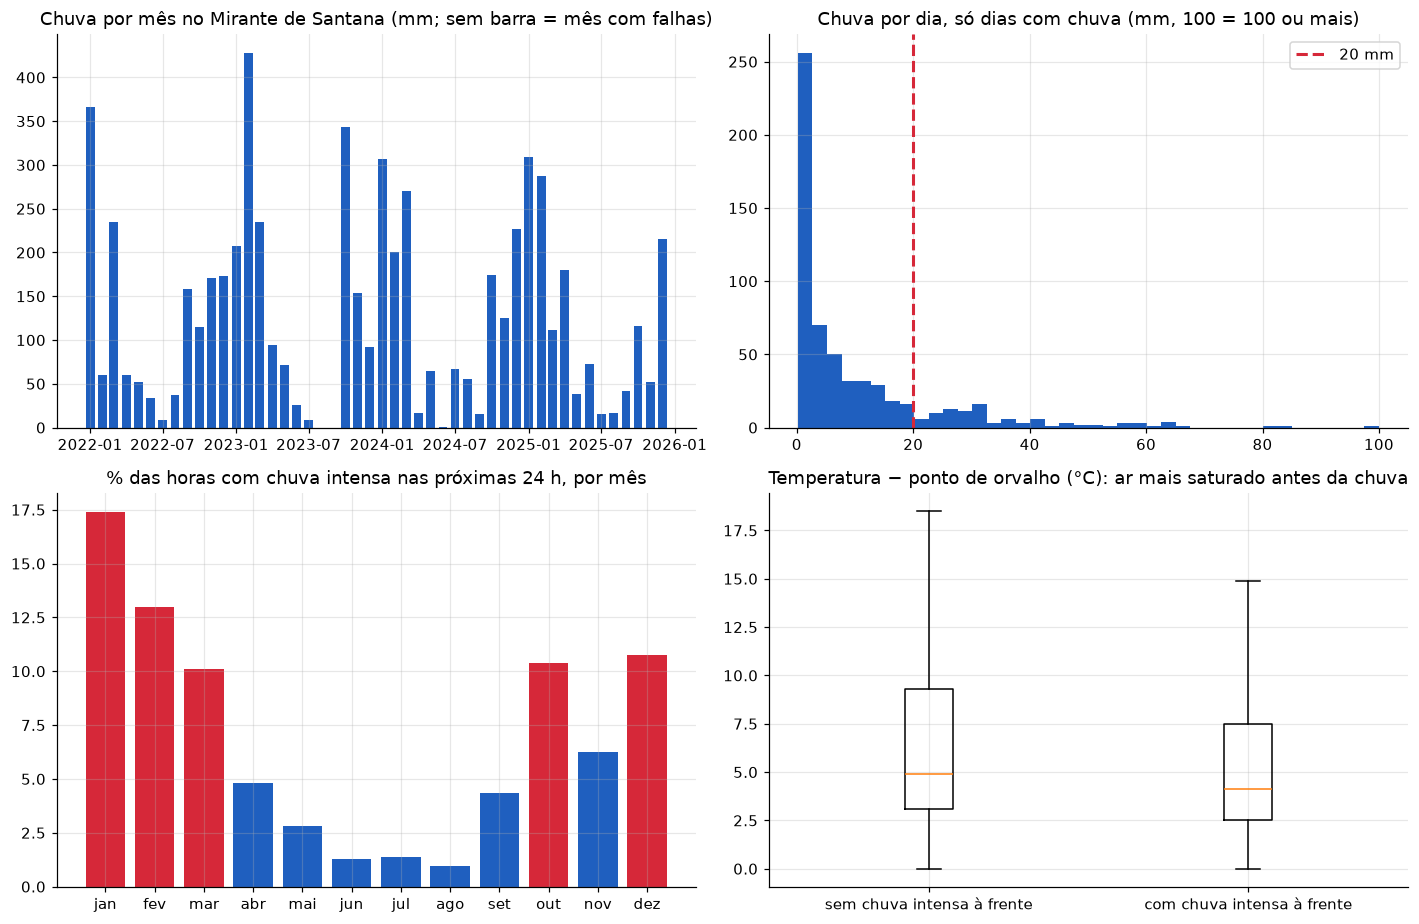

Dias com 20 mm ou mais: 98 de 1424 dias com medição (6.9%).
Meses com mais de 20% de horas sem medição de chuva na A701: {'2023-08': 25.0, '2023-09': 39.0} (sensor com falha; essas horas não viram alvo inventado)
Desbalanceamento: a classe positiva é rara, então acurácia engana. Usamos precisão, recall, F1 e PR-AUC.


In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))
mensal = c.resample('MS').sum(min_count=600)
ax[0, 0].bar(mensal.index, mensal.values, width=22, color=AZUL)
ax[0, 0].set_title('Chuva por mês no Mirante de Santana (mm; sem barra = mês com falhas)')

diaria = c.tz_convert('America/Sao_Paulo').resample('D').sum(min_count=20)
ax[0, 1].hist(diaria[diaria > 0].clip(upper=100), bins=40, color=AZUL)
ax[0, 1].axvline(LIMITE_MM, color=VERMELHO, ls='--', lw=2, label=f'{LIMITE_MM} mm')
ax[0, 1].set_title('Chuva por dia, só dias com chuva (mm, 100 = 100 ou mais)')
ax[0, 1].legend()

por_mes = base.groupby('mes').alvo.mean() * 100
ax[1, 0].bar(por_mes.index, por_mes.values, color=[VERMELHO if v >= 10 else AZUL for v in por_mes.values])
ax[1, 0].set_xticks(range(1, 13), ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez'])
ax[1, 0].set_title('% das horas com chuva intensa nas próximas 24 h, por mês')

grupos = [base.loc[base.alvo == k, 'deficit_orvalho_c'].dropna() for k in (0, 1)]
ax[1, 1].boxplot(grupos, showfliers=False)
ax[1, 1].set_xticks([1, 2], ['sem chuva intensa à frente', 'com chuva intensa à frente'])
ax[1, 1].set_title('Temperatura − ponto de orvalho (°C): ar mais saturado antes da chuva')
fig.tight_layout(); fig.savefig(SAIDA / 'analise_exploratoria.png', dpi=150); plt.show()

dias_intensos = int((diaria >= LIMITE_MM).sum())
print(f'Dias com {LIMITE_MM} mm ou mais: {dias_intensos} de {diaria.notna().sum()} dias com medição '
      f'({dias_intensos / diaria.notna().sum():.1%}).')
falhas = c.isna().groupby(c.index.strftime('%Y-%m')).mean().mul(100).round(0)
print('Meses com mais de 20% de horas sem medição de chuva na A701:', falhas[falhas > 20].to_dict(),
      '(sensor com falha; essas horas não viram alvo inventado)')
print('Desbalanceamento: a classe positiva é rara, então acurácia engana. Usamos precisão, recall, F1 e PR-AUC.')

## 3. Divisão treino/teste pela ordem do tempo

Em séries temporais, embaralhar os dados vaza o futuro para o treino. Por isso:
- **Treino:** os primeiros 80% do período. **Teste:** os 20% finais, usados **uma única vez**, no fim.
- **Folga de 24 h** entre treino e teste: a janela do alvo da última hora de treino não invade o teste.
- A imputação de ausentes fica **dentro do pipeline**, então a mediana usada vem só do treino.

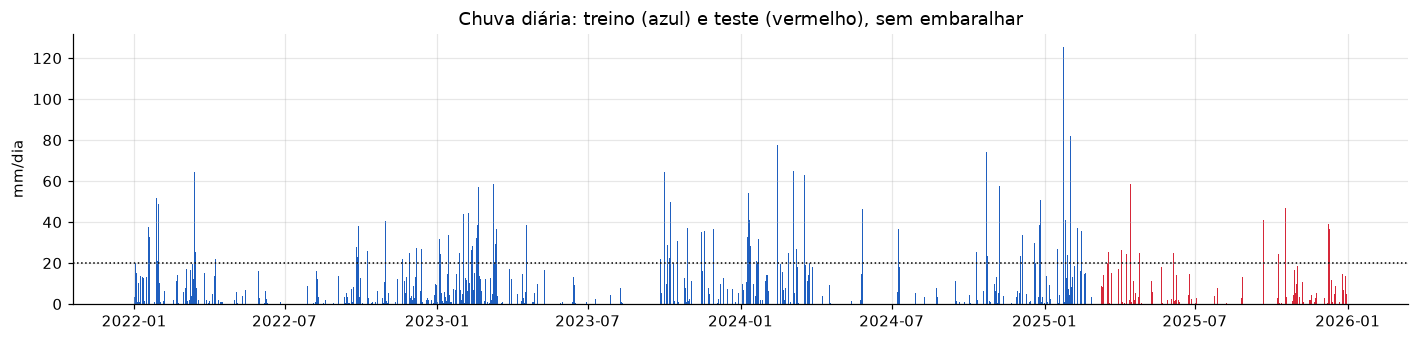

,início,fim,exemplos,positivos,taxa de positivos
treino,01/01/2022,07/03/2025,25808,2014,7.8%
teste,08/03/2025,30/12/2025,6430,264,4.1%


In [6]:
corte = int(len(base) * 0.8)
treino = base.iloc[:corte]
teste = base.iloc[corte:]
teste = teste.loc[treino.index.max() + pd.Timedelta(hours=HORIZONTE_H):]   # folga de 24 h
Xtr, ytr = treino[FEATURES], treino['alvo']
Xte, yte = teste[FEATURES], teste['alvo']

resumo_divisao = pd.DataFrame({
    'início': [treino.index.min().strftime('%d/%m/%Y'), teste.index.min().strftime('%d/%m/%Y')],
    'fim': [treino.index.max().strftime('%d/%m/%Y'), teste.index.max().strftime('%d/%m/%Y')],
    'exemplos': [len(treino), len(teste)],
    'positivos': [int(ytr.sum()), int(yte.sum())],
    'taxa de positivos': [f'{ytr.mean():.1%}', f'{yte.mean():.1%}']}, index=['treino', 'teste'])

fig, ax = plt.subplots(figsize=(13, 3.2))
diaria_utc = c.resample('D').sum(min_count=20)
cores = np.where(diaria_utc.index < teste.index.min().floor('D'), AZUL, VERMELHO)
ax.bar(diaria_utc.index, diaria_utc.values, width=1, color=cores)
ax.axhline(LIMITE_MM, color='k', ls=':', lw=1)
ax.set_title('Chuva diária: treino (azul) e teste (vermelho), sem embaralhar')
ax.set_ylabel('mm/dia')
fig.tight_layout(); fig.savefig(SAIDA / 'divisao_treino_teste.png', dpi=150); plt.show()
resumo_divisao

## 4. Modelo escolhido: Random Forest

| Opção | Por que **não** foi a escolha |
|---|---|
| LSTM | precisa de muito mais dados para não decorar; temos 4 anos de uma estação e só 7% de positivos |
| MLP | exige padronização, é sensível a ausentes e a hiperparâmetros, e é difícil de explicar ao cidadão |
| XGBoost | ótima opção, mas com mais hiperparâmetros sensíveis e risco maior de sobreajuste com poucos positivos |
| KMeans + PCA | não supervisionado: não responde "vai chover forte?" |

**Por que Random Forest:** funciona bem com dados tabulares e relações não lineares (umidade alta **e** pressão caindo); não precisa padronizar as variáveis; `class_weight='balanced_subsample'` compensa a raridade da chuva intensa; a média de muitas árvores reduz o sobreajuste; e a importância das variáveis permite explicar o farol para o morador.

## 5. Treino com 24 combinações de 3 hiperparâmetros

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `max_depth` | 4, 6, 8, 12 | profundidade das árvores (quanto mais funda, mais pode decorar) |
| `min_samples_leaf` | 10, 30, 100 | mínimo de exemplos por folha (folhas grandes generalizam mais) |
| `max_features` | `'sqrt'`, 0.5 | quantas variáveis cada divisão sorteia |

`n_estimators` fica fixo em 300 árvores. **Validação cruzada temporal** (`TimeSeriesSplit`, 4 dobras, folga de 24 h) **somente no treino**. A métrica de escolha é a **PR-AUC** (precisão média), que não depende de um limiar e é a mais honesta com classes raras. Guardamos também a PR-AUC no próprio pedaço de treino de cada dobra, para enxergar o sobreajuste.

In [7]:
GRADE = list(ParameterGrid({'max_depth': [4, 6, 8, 12], 'min_samples_leaf': [10, 30, 100],
                            'max_features': ['sqrt', 0.5]}))
CV = TimeSeriesSplit(n_splits=4, gap=HORIZONTE_H)

def novo_modelo(**p):
    return Pipeline([('imputar', SimpleImputer(strategy='median')),
                     ('rf', RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                                   n_jobs=-1, random_state=SEMENTE, **p))])

linhas = []
for i, p in enumerate(GRADE, 1):
    ap_tr, ap_va, f1_va = [], [], []
    for it, iv in CV.split(Xtr):
        m = novo_modelo(**p).fit(Xtr.iloc[it], ytr.iloc[it])
        ap_tr.append(average_precision_score(ytr.iloc[it], m.predict_proba(Xtr.iloc[it])[:, 1]))
        pv = m.predict_proba(Xtr.iloc[iv])[:, 1]
        ap_va.append(average_precision_score(ytr.iloc[iv], pv))
        f1_va.append(f1_score(ytr.iloc[iv], pv >= 0.5, zero_division=0))
    linhas.append({**p, 'pr_auc_treino': np.mean(ap_tr), 'pr_auc_validacao': np.mean(ap_va),
                   'pr_auc_validacao_desvio': np.std(ap_va), 'f1_validacao': np.mean(f1_va)})
    print(f"{i:02d}/{len(GRADE)}  depth={p['max_depth']:>2}  leaf={p['min_samples_leaf']:>3}  "
          f"feat={str(p['max_features']):>4}  PR-AUC treino={np.mean(ap_tr):.3f}  validação={np.mean(ap_va):.3f}")

busca = pd.DataFrame(linhas).sort_values('pr_auc_validacao', ascending=False).reset_index(drop=True)
busca.to_csv(SAIDA / 'busca_hiperparametros.csv', index=False, float_format='%.4f')
MELHOR = {k: busca.loc[0, k] for k in ('max_depth', 'min_samples_leaf', 'max_features')}
MELHOR = {k: (int(v) if isinstance(v, (int, np.integer, float)) and float(v).is_integer() else
              (float(v) if not isinstance(v, str) else v)) for k, v in MELHOR.items()}
print('\nMelhor combinação na validação cruzada:', MELHOR)
busca.head(8).round(3)

01/24  depth= 4  leaf= 10  feat=sqrt  PR-AUC treino=0.465  validação=0.190


02/24  depth= 4  leaf= 30  feat=sqrt  PR-AUC treino=0.454  validação=0.190


03/24  depth= 4  leaf=100  feat=sqrt  PR-AUC treino=0.398  validação=0.188


04/24  depth= 4  leaf= 10  feat= 0.5  PR-AUC treino=0.490  validação=0.180


05/24  depth= 4  leaf= 30  feat= 0.5  PR-AUC treino=0.476  validação=0.182


06/24  depth= 4  leaf=100  feat= 0.5  PR-AUC treino=0.401  validação=0.179


... (15 outputs left out)

22/24  depth=12  leaf= 10  feat= 0.5  PR-AUC treino=0.968  validação=0.161


23/24  depth=12  leaf= 30  feat= 0.5  PR-AUC treino=0.900  validação=0.170


24/24  depth=12  leaf=100  feat= 0.5  PR-AUC treino=0.601  validação=0.179

Melhor combinação na validação cruzada: {'max_depth': 6, 'min_samples_leaf': 100, 'max_features': 'sqrt'}


,max_depth,max_features,min_samples_leaf,pr_auc_treino,pr_auc_validacao,pr_auc_validacao_desvio,f1_validacao
0,6,sqrt,100,0.487,0.193,0.051,0.270
1,12,sqrt,100,0.571,0.192,0.052,0.271
2,8,sqrt,100,0.544,0.192,0.050,0.269
3,4,sqrt,10,0.465,0.190,0.044,0.260
4,4,sqrt,30,0.454,0.190,0.044,0.262
5,4,sqrt,100,0.398,0.188,0.042,0.269
6,8,sqrt,30,0.748,0.188,0.050,0.246
7,12,sqrt,30,0.865,0.187,0.051,0.224


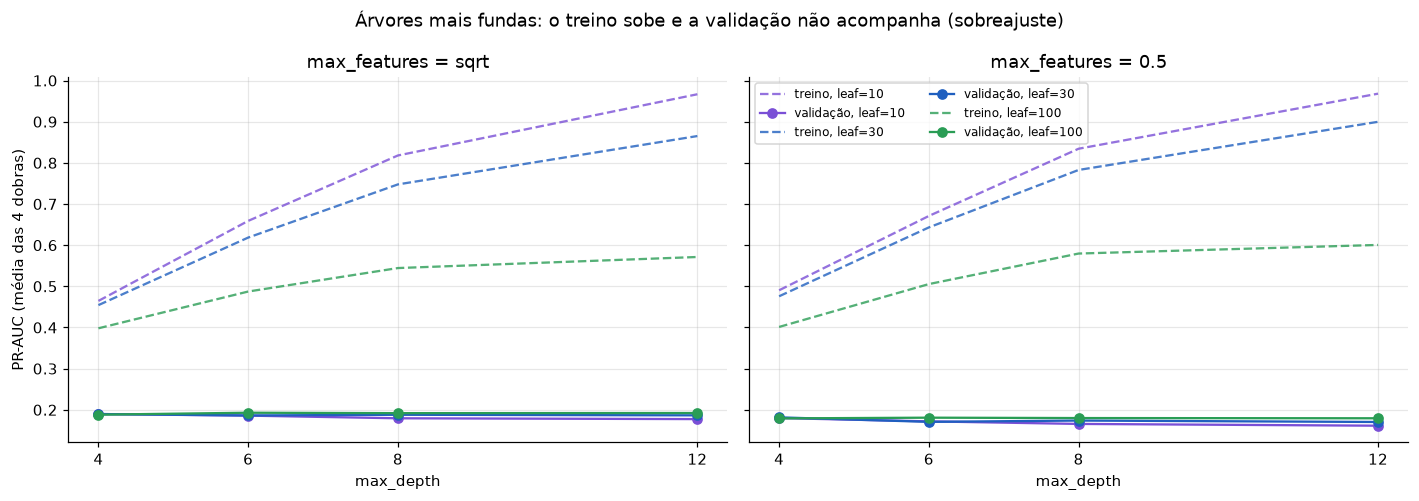

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for eixo, mf in zip(ax, ['sqrt', 0.5]):
    parte = busca[busca.max_features.astype(str) == str(mf)]
    for leaf, cor in zip([10, 30, 100], ['#7a4fd6', AZUL, VERDE]):
        linha = parte[parte.min_samples_leaf == leaf].sort_values('max_depth')
        eixo.plot(linha.max_depth, linha.pr_auc_treino, '--', color=cor, alpha=.8, label=f'treino, leaf={leaf}')
        eixo.plot(linha.max_depth, linha.pr_auc_validacao, '-o', color=cor, label=f'validação, leaf={leaf}')
    eixo.set_title(f"max_features = {mf}")
    eixo.set_xlabel('max_depth'); eixo.set_xticks([4, 6, 8, 12])
ax[0].set_ylabel('PR-AUC (média das 4 dobras)')
ax[1].legend(fontsize=8, ncol=2)
fig.suptitle('Árvores mais fundas: o treino sobe e a validação não acompanha (sobreajuste)')
fig.tight_layout(); fig.savefig(SAIDA / 'busca_hiperparametros.png', dpi=150); plt.show()

### Limiares do farol (definidos só com o treino)
O modelo devolve uma **probabilidade**. Para virar farol, precisamos de dois cortes. Eles são escolhidos com previsões **fora da amostra** dentro do treino (cada dobra da validação cruzada prevê um trecho que não viu), sem tocar no teste:
- **Vermelho:** o corte que dá o melhor F1 (equilíbrio entre acertar e não alarmar à toa).
- **Amarelo:** o corte mais alto que ainda pega **80%** das horas que antecedem chuva intensa (atenção, sem pânico).

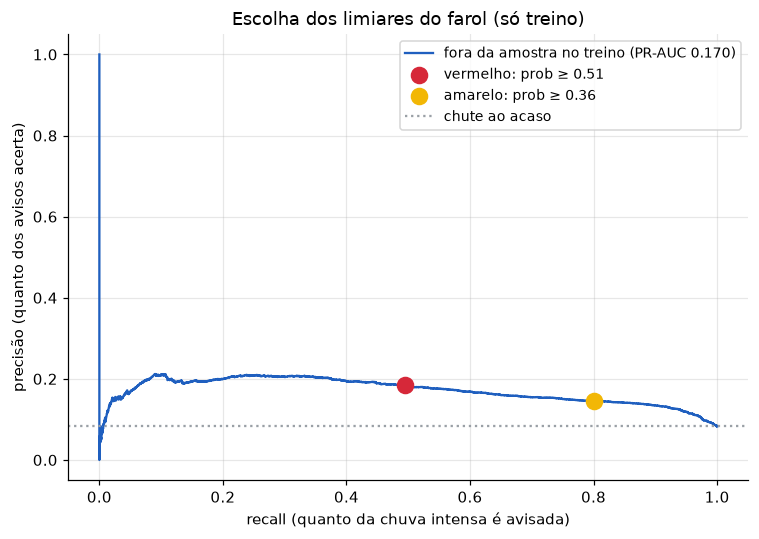

Limiar amarelo = 0.356 | limiar vermelho = 0.512


In [9]:
oof = pd.Series(np.nan, index=Xtr.index)
for it, iv in CV.split(Xtr):
    m = novo_modelo(**MELHOR).fit(Xtr.iloc[it], ytr.iloc[it])
    oof.iloc[iv] = m.predict_proba(Xtr.iloc[iv])[:, 1]
tem = oof.notna()
prec, rec, cortes = precision_recall_curve(ytr[tem], oof[tem])
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
i_verm = int(np.argmax(f1s))
LIMIAR_VERMELHO = float(cortes[i_verm])
i_amar = int(np.where(rec[:-1] >= 0.80)[0].max())
LIMIAR_AMARELO = float(min(cortes[i_amar], LIMIAR_VERMELHO))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(rec, prec, color=AZUL, label=f'fora da amostra no treino (PR-AUC {average_precision_score(ytr[tem], oof[tem]):.3f})')
ax.scatter(rec[i_verm], prec[i_verm], s=110, color=VERMELHO, zorder=3, label=f'vermelho: prob ≥ {LIMIAR_VERMELHO:.2f}')
ax.scatter(rec[i_amar], prec[i_amar], s=110, color=AMARELO, zorder=3, label=f'amarelo: prob ≥ {LIMIAR_AMARELO:.2f}')
ax.axhline(ytr[tem].mean(), color=CINZA, ls=':', label='chute ao acaso')
ax.set_xlabel('recall (quanto da chuva intensa é avisada)'); ax.set_ylabel('precisão (quanto dos avisos acerta)')
ax.set_title('Escolha dos limiares do farol (só treino)'); ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(SAIDA / 'limiares_farol.png', dpi=150); plt.show()
print(f'Limiar amarelo = {LIMIAR_AMARELO:.3f} | limiar vermelho = {LIMIAR_VERMELHO:.3f}')

## 6. Resultados em treino e teste

O modelo final é treinado com **todo** o treino e avaliado uma única vez no teste. As métricas usam o limiar **vermelho**; ROC-AUC e PR-AUC não dependem de limiar.

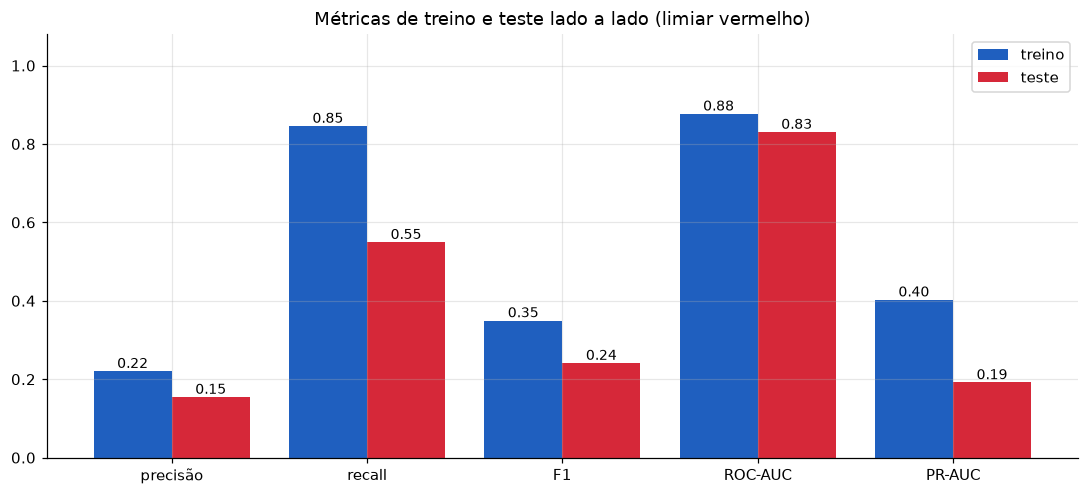

,precisão,recall,F1,ROC-AUC,PR-AUC
treino,0.220,0.846,0.350,0.877,0.403
teste,0.154,0.549,0.241,0.830,0.192
treino − teste,0.066,0.296,0.109,0.047,0.211


In [10]:
final = novo_modelo(**MELHOR).fit(Xtr, ytr)
proba = {'treino': final.predict_proba(Xtr)[:, 1], 'teste': final.predict_proba(Xte)[:, 1]}
reais = {'treino': ytr, 'teste': yte}

def avaliar(y, score, limiar):
    alerta = score >= limiar
    return {'precisão': precision_score(y, alerta, zero_division=0), 'recall': recall_score(y, alerta, zero_division=0),
            'F1': f1_score(y, alerta, zero_division=0), 'ROC-AUC': roc_auc_score(y, score),
            'PR-AUC': average_precision_score(y, score)}

resultado = pd.DataFrame({n: avaliar(reais[n], proba[n], LIMIAR_VERMELHO) for n in ('treino', 'teste')}).T
resultado.loc['treino − teste'] = resultado.loc['treino'] - resultado.loc['teste']

fig, ax = plt.subplots(figsize=(10, 4.6))
nomes = list(resultado.columns); x = np.arange(len(nomes))
for desloc, conj, cor in [(-.2, 'treino', AZUL), (.2, 'teste', VERMELHO)]:
    barras = ax.bar(x + desloc, resultado.loc[conj], .4, label=conj, color=cor)
    ax.bar_label(barras, fmt='%.2f', fontsize=9)
ax.set_xticks(x, nomes); ax.set_ylim(0, 1.08); ax.legend()
ax.set_title('Métricas de treino e teste lado a lado (limiar vermelho)')
fig.tight_layout(); fig.savefig(SAIDA / 'metricas_treino_teste.png', dpi=150); plt.show()
resultado.round(3)

### Comparação com regras simples (o modelo vale a pena?)
Um modelo só se justifica se superar regras que qualquer pessoa faria. Os parâmetros das regras também são ajustados **só no treino**:
- **Sempre "não chove forte"** (classe majoritária)
- **Persistência:** alerta se já choveu X mm ou mais nas últimas 24 h
- **Estação do ano:** alerta em todas as horas de dezembro a março

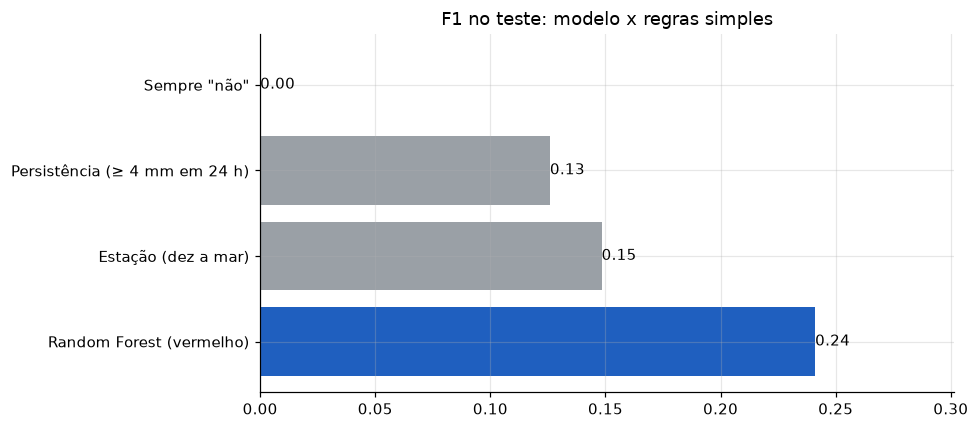

,precisão,recall,F1,PR-AUC
"Sempre ""não""",0.000,0.000,0.000,NaN
Persistência (≥ 4 mm em 24 h),0.082,0.273,0.126,0.054
Estação (dez a mar),0.093,0.367,0.148,NaN
Random Forest (vermelho),0.154,0.549,0.241,0.192


In [11]:
def melhor_x_persistencia():
    candidatos = np.arange(1, 41)
    return max(candidatos, key=lambda x0: f1_score(ytr, Xtr.chuva_ult_24h.fillna(0) >= x0, zero_division=0))
X_PERSIST = int(melhor_x_persistencia())
regras = {
    'Sempre "não"': (np.zeros(len(yte)), None),
    f'Persistência (≥ {X_PERSIST} mm em 24 h)': ((Xte.chuva_ult_24h.fillna(0) >= X_PERSIST).astype(int), Xte.chuva_ult_24h.fillna(0)),
    'Estação (dez a mar)': (Xte.mes.isin([12, 1, 2, 3]).astype(int), None),
    'Random Forest (vermelho)': ((proba['teste'] >= LIMIAR_VERMELHO).astype(int), proba['teste']),
}
comparacao = pd.DataFrame({nome: {'precisão': precision_score(yte, p, zero_division=0), 'recall': recall_score(yte, p),
                                   'F1': f1_score(yte, p, zero_division=0),
                                   'PR-AUC': average_precision_score(yte, s) if s is not None else np.nan}
                           for nome, (p, s) in regras.items()}).T

fig, ax = plt.subplots(figsize=(9, 4))
cores = [CINZA, CINZA, CINZA, AZUL]
barras = ax.barh(comparacao.index, comparacao.F1, color=cores)
ax.bar_label(barras, fmt='%.2f'); ax.set_xlim(0, max(comparacao.F1) * 1.25)
ax.set_title('F1 no teste: modelo x regras simples'); ax.invert_yaxis()
fig.tight_layout(); fig.savefig(SAIDA / 'comparacao_regras.png', dpi=150); plt.show()
comparacao.round(3)

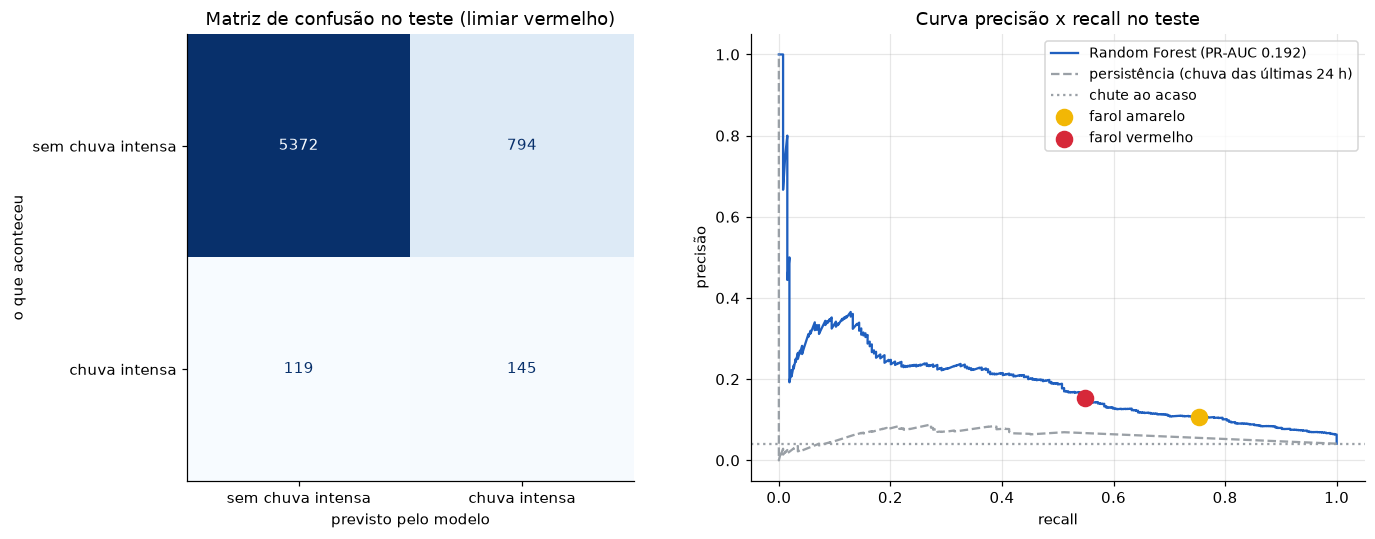

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(yte, proba['teste'] >= LIMIAR_VERMELHO, ax=ax[0], cmap='Blues', colorbar=False,
                                        display_labels=['sem chuva intensa', 'chuva intensa'])
ax[0].set_title('Matriz de confusão no teste (limiar vermelho)'); ax[0].grid(False)
ax[0].set_xlabel('previsto pelo modelo'); ax[0].set_ylabel('o que aconteceu')
p_te, r_te, _ = precision_recall_curve(yte, proba['teste'])
ax[1].plot(r_te, p_te, color=AZUL, label=f"Random Forest (PR-AUC {average_precision_score(yte, proba['teste']):.3f})")
p_pe, r_pe, _ = precision_recall_curve(yte, Xte.chuva_ult_24h.fillna(0))
ax[1].plot(r_pe, p_pe, color=CINZA, ls='--', label='persistência (chuva das últimas 24 h)')
ax[1].axhline(yte.mean(), color=CINZA, ls=':', label='chute ao acaso')
for lim, cor, nome in [(LIMIAR_AMARELO, AMARELO, 'amarelo'), (LIMIAR_VERMELHO, VERMELHO, 'vermelho')]:
    a = proba['teste'] >= lim
    ax[1].scatter(recall_score(yte, a), precision_score(yte, a, zero_division=0), s=110, color=cor, zorder=3, label=f'farol {nome}')
ax[1].set_xlabel('recall'); ax[1].set_ylabel('precisão'); ax[1].legend(fontsize=9)
ax[1].set_title('Curva precisão x recall no teste')
fig.tight_layout(); fig.savefig(SAIDA / 'matriz_confusao_e_curva_pr.png', dpi=150); plt.show()

### O que mais pesa na decisão
Importância por **permutação** no teste: embaralhamos uma variável por vez e medimos quanto a PR-AUC cai. Quanto maior a queda, mais o modelo depende daquela informação.

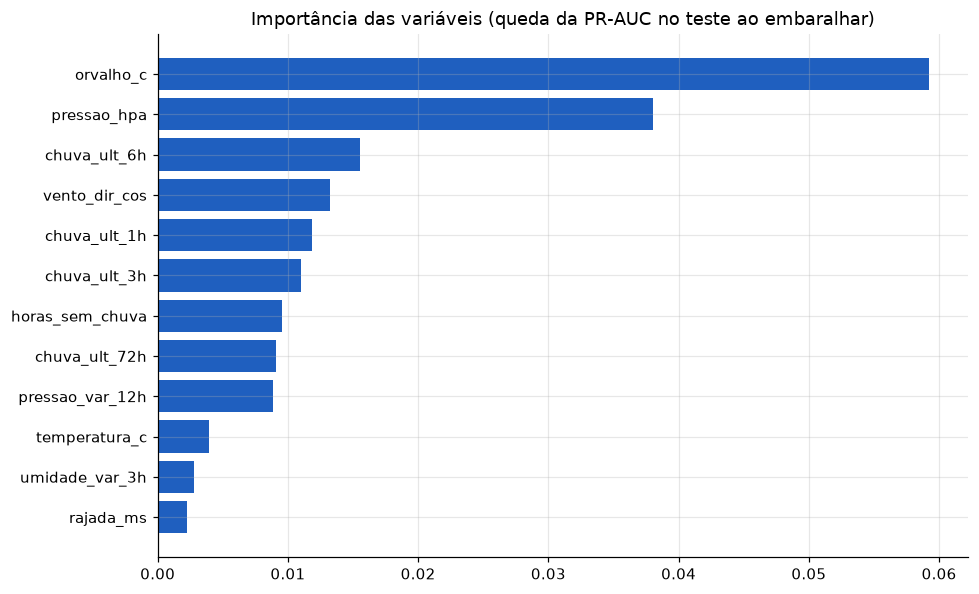

orvalho_c          0.0593
pressao_hpa        0.0380
chuva_ult_6h       0.0155
vento_dir_cos      0.0132
chuva_ult_1h       0.0119
chuva_ult_3h       0.0110
horas_sem_chuva    0.0095
chuva_ult_72h      0.0091
dtype: float64

In [13]:
imp = permutation_importance(final, Xte, yte, scoring='average_precision', n_repeats=5, random_state=SEMENTE, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
top = importancia.tail(12)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.values, color=AZUL)
ax.set_title('Importância das variáveis (queda da PR-AUC no teste ao embaralhar)')
fig.tight_layout(); fig.savefig(SAIDA / 'importancia_variaveis.png', dpi=150); plt.show()
importancia.sort_values(ascending=False).head(8).round(4)

## 7. O que isso significa para o morador

Métricas por hora são difíceis de entender. Então olhamos o período de teste como o morador vive: **dia a dia** (horário de Brasília).
- **Dia de chuva forte:** dia com 20 mm ou mais no Mirante de Santana.
- **Avisou:** o farol acendeu (vermelho, ou amarelo/vermelho) em algum momento **na véspera ou no próprio dia**.
- **Alarme falso:** dia em que o farol acendeu e a chuva forte não veio nem naquele dia nem no seguinte.

Os limiares são os mesmos escolhidos com o treino: nada aqui foi ajustado olhando o teste.

In [14]:
p_local = pd.Series(proba['teste'], index=Xte.index).tz_convert('America/Sao_Paulo')
chuva_dia = c.tz_convert('America/Sao_Paulo').resample('D').sum(min_count=20)
dias = chuva_dia.loc[p_local.index.min().normalize():p_local.index.max().normalize()]
forte = (dias >= LIMITE_MM)
meses_teste = len(dias) / 30.4

def leitura(limiar):
    acendeu = (p_local >= limiar).astype(float).resample('D').max().reindex(dias.index).fillna(0).astype(bool)
    avisou = acendeu | acendeu.shift(1, fill_value=False)
    falso = acendeu & ~forte & ~forte.shift(-1, fill_value=False) & dias.notna()
    return {'dias com farol aceso': int(acendeu.sum()), 'dias de chuva forte avisados': int((avisou & forte).sum()),
            'alarmes falsos (dias)': int(falso.sum()), 'alarmes falsos por mês': round(falso.sum() / meses_teste, 1)}

farol = pd.Series(np.select([proba['teste'] >= LIMIAR_VERMELHO, proba['teste'] >= LIMIAR_AMARELO],
                            ['vermelho', 'amarelo'], 'verde'), index=Xte.index)
dist_farol = (farol.value_counts(normalize=True) * 100).reindex(['verde', 'amarelo', 'vermelho']).round(1)
leituras = {'amarelo ou vermelho': leitura(LIMIAR_AMARELO), 'vermelho': leitura(LIMIAR_VERMELHO)}
leitura_dias = pd.DataFrame.from_dict(leituras, orient='index').astype(object)
cidadao = {'dias_no_teste': len(dias), 'meses_no_teste': round(meses_teste, 1), 'dias_de_chuva_forte': int(forte.sum()),
           'leitura_por_dia': leituras,
           'horas_vermelhas_que_acertaram_pct': round(100 * precision_score(yte, farol == 'vermelho', zero_division=0), 1),
           'tempo_em_cada_cor_pct': dist_farol.to_dict()}
v = cidadao['leitura_por_dia']['vermelho']
print(f"Teste: {len(dias)} dias ({meses_teste:.1f} meses de 2025), com {int(forte.sum())} dias de chuva forte.")
print(f"Farol VERMELHO: avisou {v['dias de chuva forte avisados']} de {int(forte.sum())} dias de chuva forte "
      f"(na véspera ou no dia), com {v['alarmes falsos (dias)']} alarmes falsos (~{v['alarmes falsos por mês']} por mês).")
print(f"Tempo em cada cor (% das horas): {dist_farol.to_dict()}")
leitura_dias

Teste: 299 dias (9.8 meses de 2025), com 11 dias de chuva forte.
Farol VERMELHO: avisou 11 de 11 dias de chuva forte (na véspera ou no dia), com 72 alarmes falsos (~7.3 por mês).
Tempo em cada cor (% das horas): {'verde': 70.8, 'amarelo': 14.6, 'vermelho': 14.6}


,dias com farol aceso,dias de chuva forte avisados,alarmes falsos (dias),alarmes falsos por mês
amarelo ou vermelho,133,11,113,11.5
vermelho,92,11,72,7.3


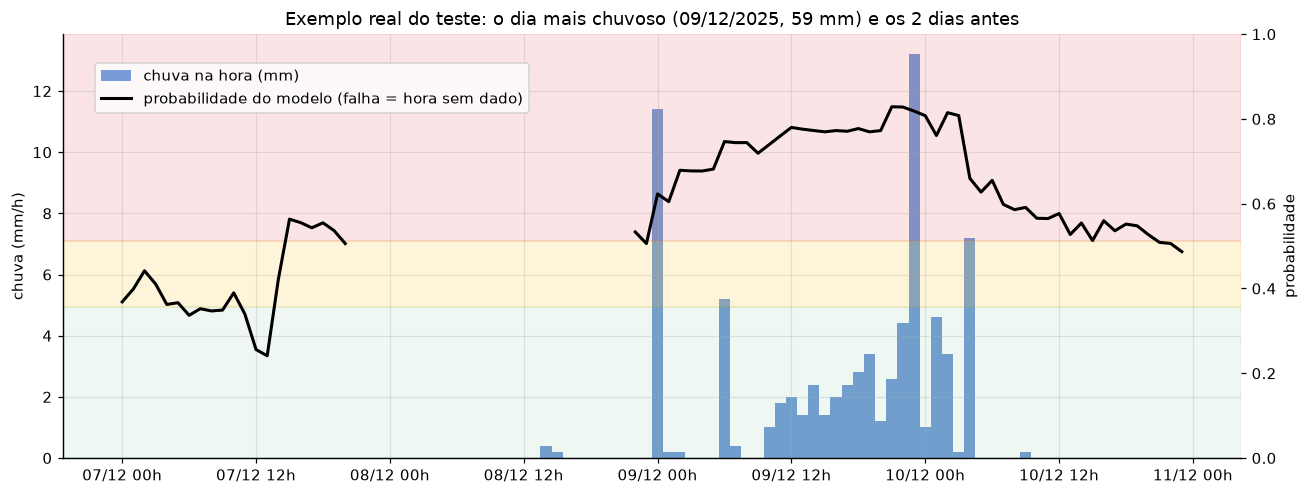

In [15]:
# exemplo real: o dia mais chuvoso do teste, visto como o morador veria o farol
import matplotlib.dates as mdates
dia_max = dias.idxmax()
inicio, fim = dia_max - pd.Timedelta(days=2), dia_max + pd.Timedelta(days=1, hours=23)
p = pd.Series(proba['teste'], index=Xte.index).asfreq('h').tz_convert('America/Sao_Paulo').loc[inicio:fim]
chuva_h = c.tz_convert('America/Sao_Paulo').loc[inicio:fim]
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.bar(chuva_h.index, chuva_h.values, width=1 / 24, color=AZUL, alpha=.6, label='chuva na hora (mm)')
ax.set_ylabel('chuva (mm/h)')
ax2 = ax.twinx(); ax2.grid(False)
ax2.axhspan(LIMIAR_VERMELHO, 1, color=VERMELHO, alpha=.12); ax2.axhspan(LIMIAR_AMARELO, LIMIAR_VERMELHO, color=AMARELO, alpha=.15)
ax2.axhspan(0, LIMIAR_AMARELO, color=VERDE, alpha=.08)
ax2.plot(p.index, p.values, color='k', lw=2, label='probabilidade do modelo (falha = hora sem dado)')
ax2.set_ylim(0, 1); ax2.set_ylabel('probabilidade')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %Hh', tz='America/Sao_Paulo'))
ax.set_title(f"Exemplo real do teste: o dia mais chuvoso ({dia_max:%d/%m/%Y}, {dias.max():.0f} mm) e os 2 dias antes")
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.88)); fig.tight_layout()
fig.savefig(SAIDA / 'exemplo_episodio.png', dpi=150); plt.show()

In [16]:
metricas = {
    'pergunta': f'chuva >= {LIMITE_MM} mm nas próximas {HORIZONTE_H} h na estação A701 (INMET)',
    'periodo_dados': [str(base.index.min()), str(base.index.max())],
    'exemplos': {'total': len(base), 'treino': len(treino), 'teste': len(teste),
                 'positivos_treino': int(ytr.sum()), 'positivos_teste': int(yte.sum())},
    'modelo': 'RandomForestClassifier(n_estimators=300, class_weight=balanced_subsample)',
    'melhores_hiperparametros': MELHOR, 'combinacoes_testadas': len(GRADE),
    'limiares_farol': {'amarelo': round(LIMIAR_AMARELO, 4), 'vermelho': round(LIMIAR_VERMELHO, 4)},
    'metricas': resultado.round(4).to_dict(orient='index'),
    'comparacao_teste': comparacao.round(4).to_dict(orient='index'),
    'leitura_cidadao': cidadao,
    'variaveis_mais_importantes': importancia.sort_values(ascending=False).head(5).round(4).to_dict(),
}
(SAIDA / 'metricas.json').write_text(json.dumps(metricas, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
print(json.dumps(metricas['metricas'], indent=2, ensure_ascii=False))

{
  "treino": {
    "precisão": 0.2204,
    "recall": 0.8456,
    "F1": 0.3496,
    "ROC-AUC": 0.8768,
    "PR-AUC": 0.4027
  },
  "teste": {
    "precisão": 0.1544,
    "recall": 0.5492,
    "F1": 0.2411,
    "ROC-AUC": 0.8302,
    "PR-AUC": 0.1917
  },
  "treino − teste": {
    "precisão": 0.0659,
    "recall": 0.2963,
    "F1": 0.1086,
    "ROC-AUC": 0.0466,
    "PR-AUC": 0.211
  }
}


## 8. Discussão: sobreajuste

Há sobreajuste, ele foi medido e controlado:

1. **Treino x teste:** o F1 cai de 0,350 para 0,241 e a PR-AUC de 0,403 para 0,192. Parte dessa queda é esperada, porque as métricas de treino são calculadas sobre dados que as árvores já viram.
2. **A prova de que a escolha foi honesta:** a PR-AUC média da validação cruzada (0,193, feita só no treino) praticamente coincide com a do teste (0,192). Ou seja, a validação previu corretamente o desempenho em dados novos, e o teste não foi usado para escolher nada.
3. **A busca mostra o sobreajuste acontecendo:** com `max_depth=12` e `min_samples_leaf=10`, a PR-AUC no treino chega a 0,968, mas na validação fica em 0,161: as árvores decoram. A combinação escolhida (`max_depth=6`, `min_samples_leaf=100`, `max_features='sqrt'`) é das mais regularizadas da grade.
4. **Mudança entre os períodos:** o teste (março a dezembro de 2025) tem metade da taxa de positivos do treino (4,1% contra 7,8%), porque cobre o inverno seco e só um começo de verão. Com menos eventos, a precisão cai naturalmente. A ROC-AUC, que não depende dessa taxa, caiu só de 0,877 para 0,830.

**Contra regras simples, no teste:** o modelo tem F1 de 0,241, contra 0,148 da regra "alertar de dezembro a março" e 0,126 da regra "já choveu 4 mm ou mais nas últimas 24 h". A PR-AUC de 0,192 é 4,7 vezes a de um chute ao acaso (0,041). As variáveis que mais pesam são o ponto de orvalho (umidade do ar), a pressão e a chuva das últimas horas, o que faz sentido na meteorologia.

## 9. Conclusão para o cidadão

**O que o resultado significa para o morador do Jardim Helena:**

- **O modelo não deixa passar a chuva forte.** Nos 11 dias de chuva forte do período de teste, o farol vermelho estava aceso na véspera ou no próprio dia em todos os 11. No dia mais chuvoso (09/12/2025, 59 mm), o vermelho acendeu já na tarde do dia 7, mais de 30 horas antes.
- **Mas ele alarma demais para mandar alguém sair de casa.** O vermelho também acendeu em 72 dias sem chuva forte (cerca de 7 por mês). Se cada vermelho virasse "saia de casa", o morador logo deixaria de acreditar no aviso.

**Por isso, no AlertaEnchente, o modelo é a primeira camada do farol, a da antecedência:**

| Farol do modelo | O que o app diz ao morador |
|---|---|
| Verde | Tudo tranquilo nas próximas 24 h |
| Amarelo | Pode chover forte: acompanhe o app |
| Vermelho | Chance alta de chuva forte: tire documentos e objetos do chão, deixe o celular carregado e combine para onde ir |

A ordem de **sair de casa** só vem com a confirmação do sensor de nível do córrego (módulo de Physical Computing) ou da Defesa Civil.

**Limitações (com honestidade):**
- O alvo é medido no Mirante de Santana, a cerca de 20 km do Jardim Helena. Não existe estação automática do INMET na Zona Leste.
- São só 4 anos de dados, com falhas do pluviômetro em agosto e setembro de 2023.
- O modelo não usa radar nem previsão numérica do tempo.
- O limite de 20 mm foi escolhido pela equipe, e chuva forte não é o mesmo que alagamento.

**Próximos passos:**
- Treinar com mais anos (a A701 mede desde 2006).
- Somar o radar meteorológico e as estações do CGE da Prefeitura.
- Treinar um segundo modelo para prever o alagamento em si, com os dados do sensor do córrego.

**ODS:**
- **ODS 11** (cidades mais seguras e resilientes): aviso antecipado para quem mora em área de risco.
- **ODS 13** (adaptação à mudança do clima): preparação para eventos extremos.
- **ODS 9** (infraestrutura e inovação): dados públicos transformados em serviço.